**AG002 | INATEL 2026.2**

Feito por:
- Bruna Magalhães | 509 | GES
- Lilyan Oliveira | 301 | GES

---

Objetivo:

Treinar, avaliar e disponibilizar um modelo de aprendizado de máquina capaz de classificar
o canal de vendas de um cliente atacadista como **HoReCa** (hotel, restaurante ou café)
ou **Retail** (varejo), a partir dos seus gastos anuais em diferentes categorias de produtos.

Conjunto de dados:

Dataset original disponível em: <https://archive.ics.uci.edu/dataset/292/wholesale+customers>

O dataset utilizado nesse trabalho foi o pré-processado, disponível em: <https://raw.githubusercontent.com/marcelovca90-inatel/AG2/main/wholesale.csv>

Etapas do projeto

1. Leitura dos dados com Pandas
2. Conversão dos valores textuais para números inteiros
3. Reordenação das colunas
4. Separação em treinamento (80%) e teste (20%)
5. Treinamento do modelo
6. Avaliação com métricas de classificação
7. Classificação de novos dados informados pelo usuário

Ferramentas

Python · Pandas · scikit-learn · Matplotlib · Joblib

Import das bibliotecas

In [2]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import cross_val_score


Ler o conjunto de dados

In [4]:
df = pd.read_csv('wholesale.csv')

Conferir os dados

In [5]:
print("Dimensões do conjunto de dados:")
print(df.shape)

print("\nNomes das colunas:")
print(df.columns.tolist())

print("\nTipos dos dados:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isnull().sum())

Dimensões do conjunto de dados:
(440, 8)

Nomes das colunas:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicatessen']

Tipos dos dados:
Channel             object
Region              object
Fresh                int64
Milk                 int64
Grocery              int64
Frozen               int64
Detergents_Paper     int64
Delicatessen         int64
dtype: object

Valores ausentes:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64


Converter as informações para números e reorganizar as colunas

In [6]:
df['Channel'] = df['Channel'].replace({
    'HoReCa': 0,
    'Retail': 1
}).astype('int64')

df['Region'] = df['Region'].replace({
    'Lisbon': 0,
    'Oporto': 1,
    'Other': 2
}).astype('int64')

df = df.reindex(columns=[
    'Region',
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicatessen',
    'Channel'
])

print("Tipos das colunas:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isnull().sum())

df.head()

Tipos das colunas:
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicatessen        int64
Channel             int64
dtype: object

Valores ausentes:
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
Channel             0
dtype: int64


/tmp/ipykernel_1593/4135894545.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Channel'] = df['Channel'].replace({
/tmp/ipykernel_1593/4135894545.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Region'] = df['Region'].replace({


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Channel
0,2,12669,9656,7561,214,2674,1338,1
1,2,7057,9810,9568,1762,3293,1776,1
2,2,6353,8808,7684,2405,3516,7844,1
3,2,13265,1196,4221,6404,507,1788,0
4,2,22615,5410,7198,3915,1777,5185,1


Separar os dados em treinamento (80%) e teste (20%)

In [7]:
X = df.drop(columns=['Channel'])
y = df['Channel']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados para treinamento:", X_train.shape)
print("Dados para teste:", X_test.shape)

print("\nProporção das classes no treino:")
print(y_train.value_counts(normalize=True).round(2))

print("\nProporção das classes no teste:")
print(y_test.value_counts(normalize=True).round(2))

Dados para treinamento: (352, 7)
Dados para teste: (88, 7)

Proporção das classes no treino:
Channel
0    0.68
1    0.32
Name: proportion, dtype: float64

Proporção das classes no teste:
Channel
0    0.68
1    0.32
Name: proportion, dtype: float64


Escolher, treinar e avaliar o desempenho do modelo de classificação

In [8]:
modelo = DecisionTreeClassifier(random_state=42)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print("Classificações realizadas:")
print(y_pred)

print("Acurácia:", accuracy_score(y_test, y_pred))

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['HoReCa', 'Retail']
))

Classificações realizadas:
[1 1 0 1 0 1 1 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 1
 0 0 1 0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0
 1 0 1 1 0 1 0 0 0 0 0 1 0 0]
Acurácia: 0.8977272727272727

Relatório de classificação:
              precision    recall  f1-score   support

      HoReCa       0.92      0.93      0.93        60
      Retail       0.85      0.82      0.84        28

    accuracy                           0.90        88
   macro avg       0.88      0.88      0.88        88
weighted avg       0.90      0.90      0.90        88



Conferir a matriz de confusão

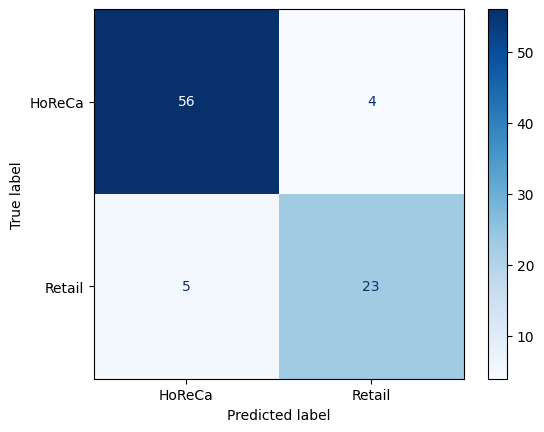

In [9]:
matriz = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['HoReCa', 'Retail']
)

disp.plot(cmap='Blues')
plt.show()

Verificar a importância de cada atributo

In [10]:
importancia = pd.DataFrame({
    'Atributo': X.columns,
    'Importância': modelo.feature_importances_
})

importancia = importancia.sort_values(
    by='Importância',
    ascending=False
)

display(importancia)

,Atributo,Importância
5,Detergents_Paper,0.714822
2,Milk,0.072912
4,Frozen,0.063439
1,Fresh,0.055291
6,Delicatessen,0.053833
3,Grocery,0.036308
0,Region,0.003395


Visualizar a árvore de decisão

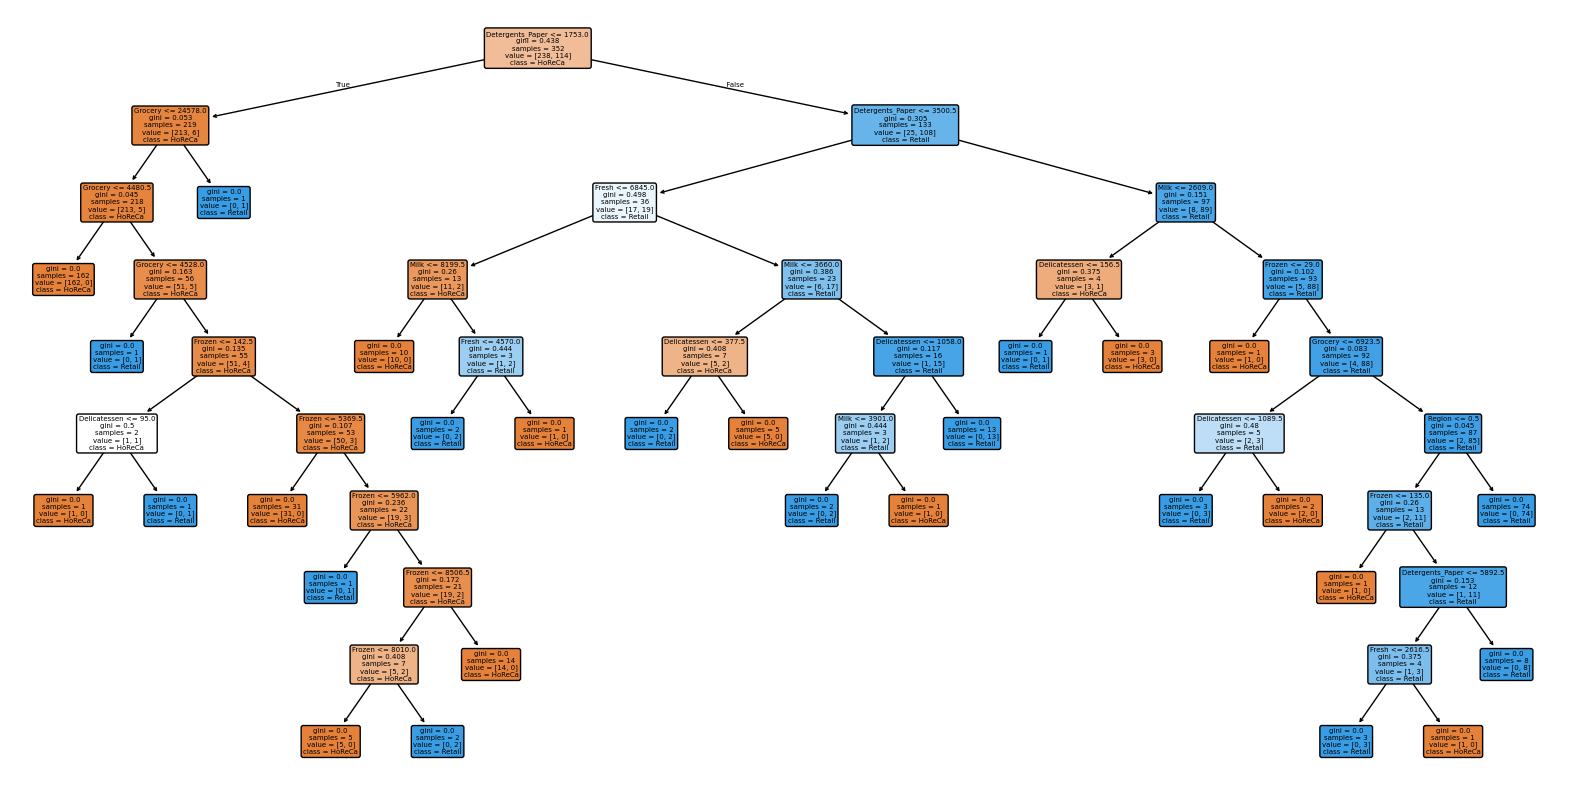

In [11]:
plt.figure(figsize=(20, 10))

plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=['HoReCa', 'Retail'],
    filled=True,
    rounded=True
)

plt.show()

Salvar o modelo treinado

In [13]:
joblib.dump(modelo, 'modelo_classificacao.pkl')

print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


   Para baixar o modelo no Colab, use: `from google.colab import files; files.download('modelo_classificacao.pkl')`

Preparar o modelo para classificar novos dados

In [14]:
modelo_carregado = joblib.load('modelo_classificacao.pkl')

COLUNAS = list(X.columns)

REGIOES = {'0': 0, '1': 1, '2': 2, 'lisbon': 0, 'oporto': 1, 'other': 2}
CANAIS = {0: 'HoReCa', 1: 'Retail'}

def ler_regiao():
    while True:
        valor = input("Região (0 = Lisbon, 1 = Oporto, 2 = Other): ").strip().lower()
        if valor in REGIOES:
            return REGIOES[valor]
        print("  Valor inválido. Digite 0, 1, 2 ou o nome da região.")

def ler_gasto(coluna):
    nome = coluna.replace('_', ' ')
    while True:
        valor = input(f"Gasto anual com {nome} (u.m.): ").strip()
        try:
            numero = int(valor)
        except ValueError:
            print("  Digite um número inteiro.")
            continue
        if numero < 0:
            print("  O gasto não pode ser negativo.")
            continue
        return numero

def classificar(dados):
    entrada = pd.DataFrame([dados], columns=COLUNAS)
    previsao = modelo_carregado.predict(entrada)[0]
    return CANAIS[int(previsao)]

Testar a classificação com dados de resposta conhecida

In [15]:
for (indice, linha), real in zip(X_test.head(5).iterrows(), y_test.head(5)):

    previsto = classificar(linha.tolist())

    print(f"Linha {indice}: previsto = {previsto} | real = {CANAIS[real]}")

Linha 281: previsto = Retail | real = Retail
Linha 426: previsto = Retail | real = HoReCa
Linha 6: previsto = HoReCa | real = Retail
Linha 82: previsto = Retail | real = Retail
Linha 103: previsto = HoReCa | real = HoReCa


Classificar novos dados informados pelo usuário

In [19]:
def classificar_novas_vendas():
    while True:
        print("\n=== Classificação de nova venda ===")

        dados = [ler_regiao()] + [ler_gasto(c) for c in COLUNAS[1:]]
        print(f"\nCanal de vendas previsto: {classificar(dados)}")

        if input("\nClassificar outra venda? (s/n): ").strip().lower() != 's':
            print("Encerrando.")
            break

classificar_novas_vendas()


=== Classificação de nova venda ===
Região (0 = Lisbon, 1 = Oporto, 2 = Other): 2
Gasto anual com Fresh (u.m.): 56082
Gasto anual com Milk (u.m.): 3504
Gasto anual com Grocery (u.m.): 8906
Gasto anual com Frozen (u.m.): 18028
Gasto anual com Detergents Paper (u.m.): 1480
Gasto anual com Delicatessen (u.m.): 2498

Canal de vendas previsto: HoReCa

Classificar outra venda? (s/n): n
Encerrando.


Teste de profundidade da árvore

In [20]:
print("Acurácia no treino:", modelo.score(X_train, y_train))
print("Acurácia no teste: ", modelo.score(X_test, y_test))

for prof in [2, 3, 4, 5, None]:
    m = DecisionTreeClassifier(max_depth=prof, random_state=42)
    notas = cross_val_score(m, X_train, y_train, cv=5)
    print(f"max_depth={prof}: {notas.mean():.3f}")

Acurácia no treino: 1.0
Acurácia no teste:  0.8977272727272727
max_depth=2: 0.889
max_depth=3: 0.892
max_depth=4: 0.895
max_depth=5: 0.900
max_depth=None: 0.889


## Conclusões

Usamos uma árvore de decisão e ela acertou o canal de venda de 79 das 88 amostras de teste (cerca de 90%), dados que ela não tinha visto no treino.

| Classe | Precisão | Recall | F1-score |
|---|---|---|---|
| HoReCa | 0,92 | 0,93 | 0,93 |
| Retail | 0,85 | 0,82 | 0,84 |

O modelo vai melhor em HoReCa do que em Retail. Desconfiamos que seja porque só 32% dos dados são Retail, então a árvore teve menos exemplos dele para aprender. Foram 5 vendas Retail classificadas como HoReCa e 4 no sentido contrário. Nos 5 exemplos que conferimos à mão, ele errou 2.

O que mais pesou na decisão foi o gasto com detergentes e papel (importância ≈ 0,71). Faz sentido: o varejo revende esse tipo de produto, enquanto hotel, restaurante e café gastam mais com fresco e congelado. A região quase não influenciou (0,003).

**Sobreajuste:** a árvore acertou 100% do treino contra 89,8% do teste, então ela decorou parte dos dados de treino. Tentamos limitar a profundidade (max_depth de 2 a 5, com validação cruzada de 5 partições), mas o resultado ficou entre 0,889 e 0,900, contra 0,889 da árvore sem limite. Uma diferença de cerca de 1 ponto, com só 352 amostras de treino, não é suficiente para dizer que limitar ajuda, então mantivemos o modelo com os parâmetros padrão.

**Limitações:** são só 440 amostras, então o resultado pode mudar com outra divisão dos dados, e não tratamos o desbalanceamento entre as classes. Com mais tempo, testaríamos outros modelos (k-NN, Naïve Bayes) para comparar com a árvore.

**Decisão que tomamos:** usamos split estratificado para treino e teste manterem a proporção original de HoReCa e Retail (68/32).